In [1]:
import torch
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable a GPU in Runtime settings.")

PyTorch: 2.11.0+cu130
Device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [2]:
%pip install -q "monai[nibabel]" matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 28.7 MB/s eta 0:00:00


In [3]:
import monai
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np

print("MONAI:", monai.__version__)
print("NumPy:", np.__version__)
print("Medical image reader: ready")

MONAI: 1.6.1
NumPy: 2.1.3
Medical image reader: ready


In [5]:
from monai.apps import DecathlonDataset

DATA_DIR = "/content/medical_data"
os.makedirs(DATA_DIR, exist_ok=True)

dataset = DecathlonDataset(
    root_dir=DATA_DIR,
    task="Task01_BrainTumour",
    section="training",
    download=True,
    num_workers=2,
)

print("Training cases:", len(dataset))
print("First case keys:", dataset[0].keys())

Task01_BrainTumour.tar: 7.09GB [02:44, 46.3MB/s]                            


2026-10-18 11:32:09,049 - INFO - Verified 'Task01_BrainTumour.tar', md5: 240a19d752f0d9e9101544901065d872.
2026-10-18 11:32:09,050 - INFO - Downloaded: /content/medical_data/Task01_BrainTumour.tar
2026-10-18 11:32:09,050 - INFO - Writing into directory: /content/medical_data.


Loading dataset: 100%|██████████| 388/388 [01:32<00:00,  4.17it/s]

Training cases: 388
First case keys: dict_keys(['image', 'label'])


In [6]:
from sklearn.model_selection import train_test_split

# Get the image/label file records.
records = [dataset[i] for i in range(len(dataset))]

print("Total cases:", len(records))
print("Image files:", records[0]["image"])
print("Label file:", records[0]["label"])

train_records, val_records = train_test_split(
    records,
    test_size=0.2,
    random_state=42,
)

print("Training cases:", len(train_records))
print("Validation cases:", len(val_records))

Total cases: 388
Image files: metatensor([[[[0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          ...,
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.]],

         [[0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          ...,
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.]],

         [[0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          ...,
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.]],

         ...,

         [[0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          ...,
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.]],

         [[0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          ...,
          [0., 0., 0., 0.],
          [0., 0., 0., 0.],
          [0., 0., 0., 0.]],

         [[0., 0., 0., 0.]

In [8]:
import torch
from monai.transforms import (
    Compose,
    EnsureChannelFirstd,
    Orientationd,
    NormalizeIntensityd,
    CropForegroundd,
    RandCropByPosNegLabeld,
    Lambdad,
    EnsureTyped,
)
from monai.data import CacheDataset, DataLoader

def remap_labels(x):
    # Original BraTS-style label 4 becomes class 3.
    return torch.where(x == 4, 3, x)

# Removed LoadImaged since dataset records already hold loaded MetaTensors.
common_transforms = [
    EnsureChannelFirstd(keys=["image"], channel_dim=-1),
    EnsureChannelFirstd(keys=["label"], channel_dim="no_channel"),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    Lambdad(keys=["label"], func=remap_labels),
    NormalizeIntensityd(
        keys=["image"], nonzero=True, channel_wise=True
    ),
    CropForegroundd(
        keys=["image", "label"],
        source_key="image",
    ),
    EnsureTyped(keys=["image", "label"]),
]

train_transform = Compose(
    common_transforms + [
        RandCropByPosNegLabeld(
            keys=["image", "label"],
            label_key="label",
            spatial_size=(96, 96, 96),
            pos=1,
            neg=1,
            num_samples=2,
        )
    ]
)

val_transform = Compose(common_transforms)

train_ds = CacheDataset(
    data=train_records,
    transform=train_transform,
    cache_rate=0.2,
    num_workers=2,
)

val_ds = CacheDataset(
    data=val_records,
    transform=val_transform,
    cache_rate=0.2,
    num_workers=2,
)

train_loader = DataLoader(
    train_ds,
    batch_size=1,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_ds,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)
Loading dataset: 100%|██████████| 15/15 [00:00<00:00, 29.46it/s]

Training batches: 310
Validation batches: 78


In [36]:
from monai.networks.nets import UNet
from monai.losses import DiceCELoss

model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=2,
).to(device)

loss_function = DiceCELoss(
    to_onehot_y=True,
    softmax=True,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5,
)

print("Model ready on:", device)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Model ready on: cuda
Trainable parameters: 1191413


In [37]:
from monai.inferers import sliding_window_inference
from monai.metrics import DiceMetric

EPOCHS = 2
best_val_dice = -1.0
history = {"train_loss": [], "val_dice": []}

def region_dice(pred, target, region):
    # pred and target are integer label volumes.
    p = region(pred)
    t = region(target)
    denominator = p.sum() + t.sum()

    if denominator.item() == 0:
        return float("nan")

    return (2.0 * (p & t).sum().float() / denominator.float()).item()

regions = {
    "WT": lambda x: x > 0,
    "TC": lambda x: (x == 1) | (x == 3),
    "ET": lambda x: x == 3,
}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for batch in train_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device).long()

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = loss_function(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / max(len(train_loader), 1)
    history["train_loss"].append(train_loss)

    model.eval()
    val_scores = {"WT": [], "TC": [], "ET": []}

    with torch.no_grad():
        for batch in val_loader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)

            logits = sliding_window_inference(
                images,
                roi_size=(96, 96, 96),
                sw_batch_size=1,
                predictor=model,
                overlap=0.25,
            )

            predictions = logits.argmax(dim=1)
            targets = labels[:, 0].long()

            for name, region_fn in regions.items():
                score = region_dice(
                    predictions[0],
                    targets[0],
                    region_fn,
                )
                if not np.isnan(score):
                    val_scores[name].append(score)

    mean_scores = {
        name: float(np.mean(values)) if values else float("nan")
        for name, values in val_scores.items()
    }

    valid_scores = [
        value for value in mean_scores.values()
        if np.isfinite(value)
    ]
    mean_dice = float(np.mean(valid_scores)) if valid_scores else 0.0
    history["val_dice"].append(mean_dice)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"loss={train_loss:.4f} | "
        f"WT={mean_scores['WT']:.4f} | "
        f"TC={mean_scores['TC']:.4f} | "
        f"ET={mean_scores['ET']:.4f}"
    )

    if mean_dice > best_val_dice:
        best_val_dice = mean_dice
        torch.save(model.state_dict(), "/content/best_brain_tumor_unet.pth")

print("Best validation mean Dice:", best_val_dice)

Epoch 1/2 | loss=0.7817 | WT=0.7798 | TC=0.7014 | ET=0.6674
Epoch 2/2 | loss=0.5201 | WT=0.7805 | TC=0.7086 | ET=0.6789
Best validation mean Dice: 0.7226877873843042


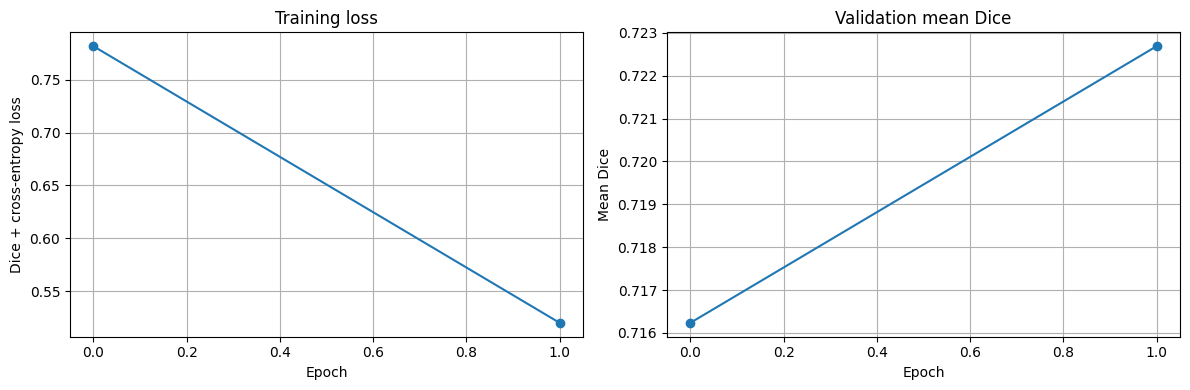

In [38]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], marker="o")
plt.title("Training loss")
plt.xlabel("Epoch")
plt.ylabel("Dice + cross-entropy loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history["val_dice"], marker="o")
plt.title("Validation mean Dice")
plt.xlabel("Epoch")
plt.ylabel("Mean Dice")
plt.grid(True)

plt.tight_layout()
plt.show()

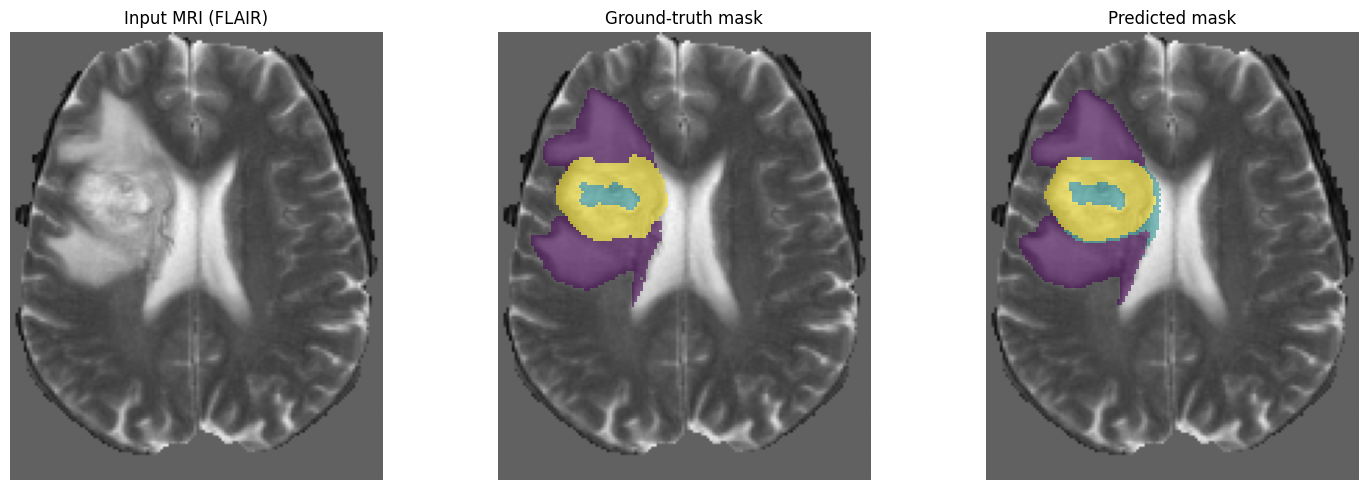

In [39]:
# Load the best checkpoint saved during training.
model.load_state_dict(
    torch.load(
        "/content/best_brain_tumor_unet.pth",
        map_location=device,
        weights_only=True,
    )
)
model.eval()

sample = val_ds[0]

# Image shape: [4, X, Y, Z]
image = sample["image"].cpu().numpy()
label = sample["label"].cpu().numpy()[0]

# Choose the axial slice with the most annotated tumor.
tumor_per_slice = (label > 0).sum(axis=(0, 1))
z = int(tumor_per_slice.argmax())

with torch.no_grad():
    input_tensor = sample["image"].unsqueeze(0).to(device)

    output = sliding_window_inference(
        input_tensor,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=model,
        overlap=0.25,
    )

    prediction = output.argmax(dim=1)[0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# FLAIR is typically the fourth input channel.
axes[0].imshow(image[3, :, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("Input MRI (FLAIR)")

axes[1].imshow(image[3, :, :, z].T, cmap="gray", origin="lower")
axes[1].imshow(
    np.ma.masked_where(label[:, :, z].T == 0, label[:, :, z].T),
    alpha=0.55,
    interpolation="nearest",
    origin="lower",
    vmin=1,
    vmax=3,
    cmap="viridis",
)
axes[1].set_title("Ground-truth mask")

axes[2].imshow(image[3, :, :, z].T, cmap="gray", origin="lower")
axes[2].imshow(
    np.ma.masked_where(
        prediction[:, :, z].T == 0,
        prediction[:, :, z].T,
    ),
    alpha=0.55,
    interpolation="nearest",
    origin="lower",
    vmin=1,
    vmax=3,
    cmap="viridis",
)
axes[2].set_title("Predicted mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [42]:
model.load_state_dict(
    torch.load(
        "/content/best_brain_tumor_unet.pth",
        map_location=device,
        weights_only=True,
    )
)
model.eval()

correct_regions = {
    "WT": lambda x: x > 0,
    "TC": lambda x: (x == 2) | (x == 3),
    "ET": lambda x: x == 3,
}

correct_scores = {name: [] for name in correct_regions}

with torch.no_grad():
    for batch in val_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        logits = sliding_window_inference(
            images,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25,
        )

        predictions = logits.argmax(dim=1)
        targets = labels[:, 0].long()

        for i in range(predictions.shape[0]):
            for name, region_fn in correct_regions.items():
                score = region_dice(
                    predictions[i],
                    targets[i],
                    region_fn,
                )

                if np.isfinite(score):
                    correct_scores[name].append(score)

for name, scores in correct_scores.items():
    if scores:
        print(
            f"{name} Dice: {np.mean(scores):.4f} "
            f"(n={len(scores)})"
        )
    else:
        print(f"{name} Dice: no valid cases")

WT Dice: 0.7805 (n=78)
TC Dice: 0.6357 (n=78)
ET Dice: 0.6789 (n=78)


In [43]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from monai.inferers import sliding_window_inference

#fine tuning
model.load_state_dict(
    torch.load(
        "/content/best_brain_tumor_unet.pth",
        map_location=device,
        weights_only=True
    )
)

# 2. Set a smaller learning rate for continued training
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=1e-5
)

# 3. Correct tumor region definitions
regions = {
    "WT": lambda x: x > 0,
    "TC": lambda x: (x == 2) | (x == 3),
    "ET": lambda x: x == 3
}

# 4. Store results
history_extra = {
    "loss": [],
    "WT": [],
    "TC": [],
    "ET": []
}

best_dice = (0.8419 + 0.7150 + 0.6691) / 3

# 5. Train for 20 additional epochs
for epoch in range(20):

    model.train()
    total_loss = 0.0

    for batch in train_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device).long()

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = loss_function(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    history_extra["loss"].append(avg_loss)

    # 6. Validate the model
    model.eval()
    scores = {name: [] for name in regions}

    with torch.no_grad():
        for batch in val_loader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)

            logits = sliding_window_inference(
                images,
                roi_size=(96, 96, 96),
                sw_batch_size=1,
                predictor=model,
                overlap=0.25
            )

            predictions = logits.argmax(dim=1)
            targets = labels[:, 0].long()

            for i in range(predictions.shape[0]):
                for name, region_fn in regions.items():
                    score = region_dice(
                        predictions[i],
                        targets[i],
                        region_fn
                    )

                    if np.isfinite(score):
                        scores[name].append(score)

    means = {
        name: float(np.mean(values)) if values else float("nan")
        for name, values in scores.items()
    }

    for name in regions:
        history_extra[name].append(means[name])

    valid = [v for v in means.values() if np.isfinite(v)]
    mean_dice = float(np.mean(valid)) if valid else 0.0

    print(
        f"Extra epoch {epoch+1}/20 | "
        f"Loss: {avg_loss:.4f} | "
        f"WT: {means['WT']:.4f} | "
        f"TC: {means['TC']:.4f} | "
        f"ET: {means['ET']:.4f}"
    )

    # Save only when the corrected validation score improves
    if mean_dice > best_dice:
        best_dice = mean_dice
        torch.save(
            model.state_dict(),
            "/content/best_brain_tumor_unet.pth"
        )
        print("  Best model saved!")

print("Training finished.")

Extra epoch 1/20 | Loss: 0.4686 | WT: 0.8149 | TC: 0.6953 | ET: 0.7031
Extra epoch 2/20 | Loss: 0.4593 | WT: 0.8216 | TC: 0.7036 | ET: 0.7077
  Best model saved!
Extra epoch 3/20 | Loss: 0.4574 | WT: 0.8271 | TC: 0.7105 | ET: 0.7148
  Best model saved!
Extra epoch 4/20 | Loss: 0.4453 | WT: 0.8244 | TC: 0.7103 | ET: 0.7130
Extra epoch 5/20 | Loss: 0.4474 | WT: 0.8322 | TC: 0.7169 | ET: 0.7232
  Best model saved!
Extra epoch 6/20 | Loss: 0.4452 | WT: 0.8303 | TC: 0.7163 | ET: 0.7202
Extra epoch 7/20 | Loss: 0.4453 | WT: 0.8334 | TC: 0.7215 | ET: 0.7221
  Best model saved!
Extra epoch 8/20 | Loss: 0.4400 | WT: 0.8370 | TC: 0.7228 | ET: 0.7243
  Best model saved!
Extra epoch 9/20 | Loss: 0.4390 | WT: 0.8339 | TC: 0.7187 | ET: 0.7207
Extra epoch 10/20 | Loss: 0.4359 | WT: 0.8356 | TC: 0.7223 | ET: 0.7272
  Best model saved!
Extra epoch 11/20 | Loss: 0.4373 | WT: 0.8440 | TC: 0.7299 | ET: 0.7278
  Best model saved!
Extra epoch 12/20 | Loss: 0.4314 | WT: 0.8465 | TC: 0.7320 | ET: 0.7279
  Bes

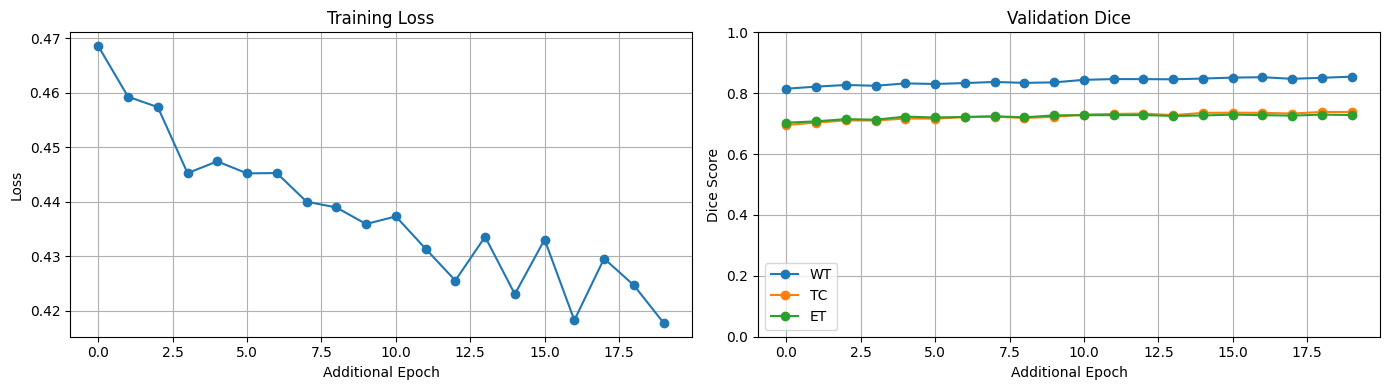

In [44]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.plot(history_extra["loss"], marker="o")
plt.title("Training Loss")
plt.xlabel("Additional Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.subplot(1, 2, 2)
for name in ["WT", "TC", "ET"]:
    plt.plot(
        history_extra[name],
        marker="o",
        label=name
    )

plt.title("Validation Dice")
plt.xlabel("Additional Epoch")
plt.ylabel("Dice Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

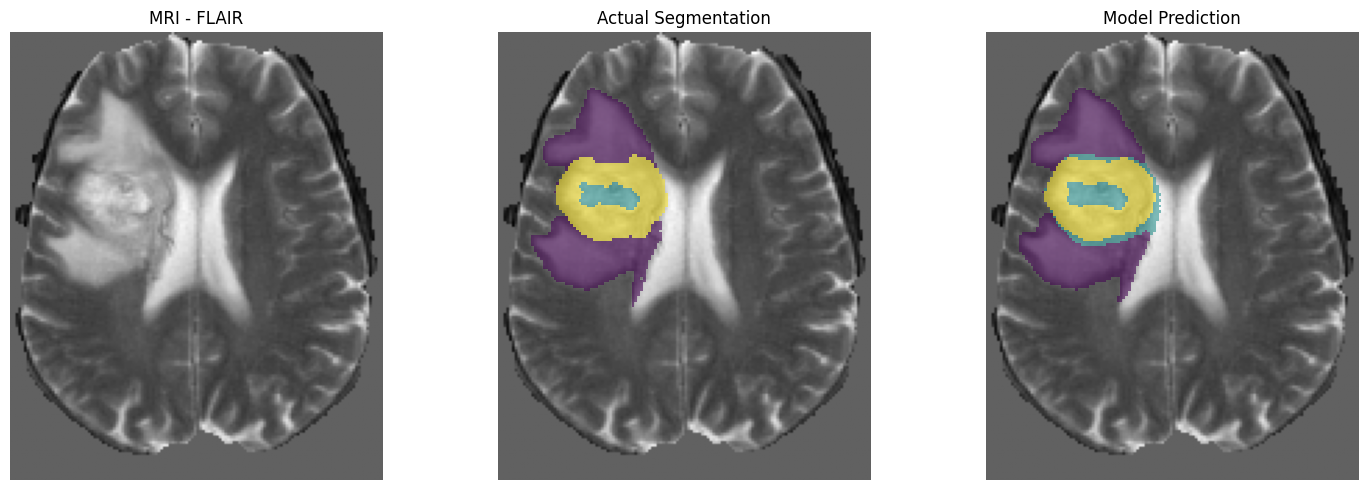

In [45]:
model.load_state_dict(
    torch.load(
        "/content/best_brain_tumor_unet.pth",
        map_location=device,
        weights_only=True
    )
)
model.eval()

sample = val_ds[0]
image = sample["image"].cpu().numpy()
label = sample["label"].cpu().numpy()[0]

with torch.no_grad():
    input_tensor = sample["image"].unsqueeze(0).to(device)

    output = sliding_window_inference(
        input_tensor,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=model,
        overlap=0.25
    )

    prediction = output.argmax(dim=1)[0].cpu().numpy()

# Find the slice with the most tumor in the reference mask
z = int((label > 0).sum(axis=(0, 1)).argmax())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image[3, :, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("MRI - FLAIR")

axes[1].imshow(image[3, :, :, z].T, cmap="gray", origin="lower")
axes[1].imshow(
    np.ma.masked_where(label[:, :, z].T == 0, label[:, :, z].T),
    cmap="viridis", alpha=0.55, origin="lower",
    interpolation="nearest", vmin=1, vmax=3
)
axes[1].set_title("Actual Segmentation")

axes[2].imshow(image[3, :, :, z].T, cmap="gray", origin="lower")
axes[2].imshow(
    np.ma.masked_where(
        prediction[:, :, z].T == 0,
        prediction[:, :, z].T
    ),
    cmap="viridis", alpha=0.55, origin="lower",
    interpolation="nearest", vmin=1, vmax=3
)
axes[2].set_title("Model Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [48]:
import torch
import os

CHECKPOINT_PATH = "/content/best_brain_tumor_unet.pth"

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT_PATH}")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.eval()

print("Best model loaded!")
print("Device:", device)

Best model loaded!
Device: cuda


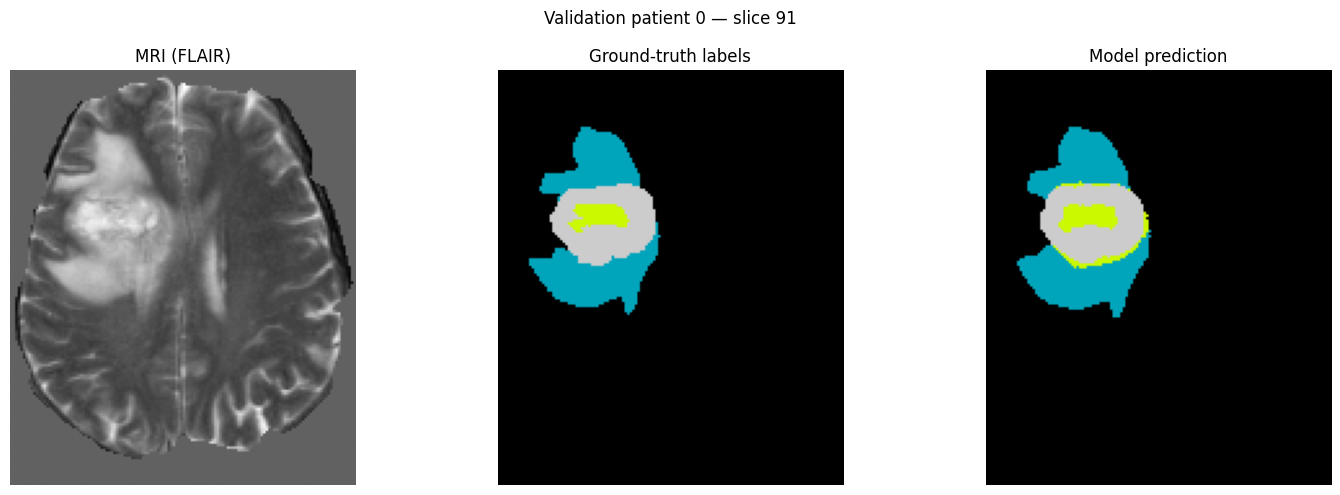

In [49]:
import matplotlib.pyplot as plt
import numpy as np
from monai.inferers import sliding_window_inference

# Choose a validation patient
case = val_ds[0]

# Add batch dimension and move MRI to GPU/selected device
image = case["image"].unsqueeze(0).to(device)
label = case["label"].detach().cpu().numpy().squeeze()

model.eval()

with torch.no_grad():
    logits = sliding_window_inference(
        inputs=image,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=model,
        overlap=0.25
    )

    prediction = torch.argmax(logits, dim=1)
    prediction = prediction[0].cpu().numpy()

# Get MRI channel 3 (usually FLAIR for this dataset)
flair = image[0, 3].detach().cpu().numpy()

# Select a slice containing the most ground-truth tumor
tumor_slices = np.where(np.any(label > 0, axis=(0, 1)))[0]

if len(tumor_slices) > 0:
    slice_idx = int(tumor_slices[len(tumor_slices) // 2])
else:
    slice_idx = flair.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(flair[:, :, slice_idx].T, cmap="gray", origin="lower")
axes[0].set_title("MRI (FLAIR)")

axes[1].imshow(label[:, :, slice_idx].T, cmap="nipy_spectral",
               vmin=0, vmax=3, origin="lower")
axes[1].set_title("Ground-truth labels")

axes[2].imshow(prediction[:, :, slice_idx].T, cmap="nipy_spectral",
               vmin=0, vmax=3, origin="lower")
axes[2].set_title("Model prediction")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"Validation patient 0 — slice {slice_idx}")
plt.tight_layout()
plt.show()

In [50]:
def dice_score(pred_mask, true_mask):
    pred_mask = pred_mask.astype(bool)
    true_mask = true_mask.astype(bool)

    denominator = pred_mask.sum() + true_mask.sum()

    if denominator == 0:
        return float("nan")

    intersection = np.logical_and(pred_mask, true_mask).sum()
    return 2.0 * intersection / denominator


# Composite tumor regions for this dataset
regions = {
    "Whole Tumor (WT)": lambda x: x > 0,
    "Tumor Core (TC)": lambda x: (x == 2) | (x == 3),
    "Enhancing Tumor (ET)": lambda x: x == 3,
}

print("Dice scores for this validation patient:\n")

for name, region_fn in regions.items():
    score = dice_score(region_fn(prediction), region_fn(label))
    print(f"{name}: {score:.4f}" if np.isfinite(score)
          else f"{name}: both masks are empty")

Dice scores for this validation patient:

Whole Tumor (WT): 0.9507
Tumor Core (TC): 0.8972
Enhancing Tumor (ET): 0.9242


In [51]:
from tqdm.auto import tqdm

region_names = ["WT", "TC", "ET"]
all_scores = {name: [] for name in region_names}

model.eval()

for case in tqdm(val_ds, desc="Evaluating validation set"):
    image = case["image"].unsqueeze(0).to(device)
    label = case["label"].detach().cpu().numpy().squeeze()

    with torch.no_grad():
        logits = sliding_window_inference(
            inputs=image,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25
        )

        pred = torch.argmax(logits, dim=1)[0].cpu().numpy()

    masks = {
        "WT": (pred > 0, label > 0),
        "TC": (np.isin(pred, [2, 3]), np.isin(label, [2, 3])),
        "ET": (pred == 3, label == 3),
    }

    for name, (pred_mask, true_mask) in masks.items():
        score = dice_score(pred_mask, true_mask)

        # Skip cases where both masks are empty
        if np.isfinite(score):
            all_scores[name].append(score)

print("\nValidation results")
for name in region_names:
    scores = all_scores[name]
    print(f"{name}: {np.mean(scores):.4f} "
          f"(evaluated cases: {len(scores)})")

mean_dice = np.mean([
    np.mean(all_scores[name])
    for name in region_names
    if len(all_scores[name]) > 0
])

print(f"\nMean regional Dice: {mean_dice:.4f}")

Evaluating validation set:   0%|          | 0/78 [00:00<?, ?it/s]


Validation results
WT: 0.8544 (evaluated cases: 78)
TC: 0.7381 (evaluated cases: 78)
ET: 0.7282 (evaluated cases: 78)

Mean regional Dice: 0.7736
